In [45]:
from typing import TypedDict
from langgraph.graph import StateGraph

In [46]:
class AgentState:
    name : str
    age : str
    result : str

In [47]:
def first_node(state : AgentState) -> AgentState:
    state['result'] = f"Hi {state['name']}!"
    return state
def second_node(state : AgentState) -> AgentState:
    state['result'] = f"{state['result']} You are {state['age']} years old!"
    return state

In [48]:
graph = StateGraph(AgentState)
graph.add_node("First",first_node)
graph.add_node("second", second_node)
graph.set_entry_point("First")
graph.add_edge("First","second")
graph.set_finish_point("second")
app = graph.compile()


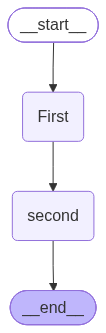

In [49]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [50]:
result01 = app.invoke({'name':'Charlie','age':'34'})

In [51]:
print(result01['result'])

Hi Charlie! You are 34 years old!


In [52]:
from typing import List
class AgentState1:
    name : str
    age : str
    skill : list
    result : str

In [61]:
def first_node(state : AgentState1) -> AgentState1:
    state['result'] = f"{state['name']}, Welcome to the system! "
    return state
def second_node(state : AgentState1) -> AgentState1:
    state['result'] = f"{state['result']}You are {state['age']} years old! "
    return state
def third_node(state : AgentState1) -> AgentState1:
    state['result'] = f"{state['result']} You have skill in {" ,".join(state['skill'])}"
    return state

In [65]:
g2 = StateGraph(AgentState1)
g2.add_node("first",first_node)
g2.add_node("second",second_node)
g2.add_node("third",third_node)

g2.set_entry_point("first")
g2.add_edge("first","second")
g2.add_edge("second","third")
g2.set_finish_point("third")
app = g2.compile()

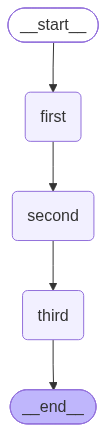

In [64]:
from IPython.display import display,Image
display(Image(app.get_graph().draw_mermaid_png()))

In [67]:
result = app.invoke({"name":"Linda","age":"31","skill":["Python","Machine Learning","and LangGraph"]})

In [68]:
print(result['result'])

Linda, Welcome to the system! You are 31 years old!  You have skill in Python ,Machine Learning ,and LangGraph
